In [1]:
# Practical 3A: Credit Card Fraud Detection using Autoencoder

# Step 1: Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


In [2]:
# --------------------------------------------------
# Stage A: Loading and preprocessing the dataset
# --------------------------------------------------

# Load credit card dataset

data = pd.read_csv("creditcard.csv")

print("Dataset Shape:", data.shape)
print("\nClass Distribution:")
print(data["Class"].value_counts())

Dataset Shape: (284807, 31)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [3]:
# Separate features and target

X = data.drop("Class", axis=1)
y = data["Class"]


In [4]:
# Split into training and testing datasets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [5]:
# Keep only normal transactions for training

X_train_normal = X_train[y_train == 0]

print("\nNormal Training Data:", X_train_normal.shape)


Normal Training Data: (227451, 30)


In [6]:
# Split normal training data into training and validation data

X_train_normal, X_val_normal = train_test_split(
    X_train_normal,
    test_size=0.1,
    random_state=42
)

In [7]:
# Scale features using only normal training data

scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

print("Training Shape:", X_train_normal.shape)
print("Validation Shape:", X_val_normal.shape)
print("Testing Shape:", X_test.shape)


Training Shape: (204705, 30)
Validation Shape: (22746, 30)
Testing Shape: (56962, 30)


In [8]:
# --------------------------------------------------
# Stage B: Defining the Autoencoder architecture
# --------------------------------------------------

input_dim = X_train_normal.shape[1]

In [9]:
# Define Autoencoder model

model = keras.Sequential([

    # Encoder
    layers.Input(shape=(input_dim,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(4, activation='relu'),

    # Decoder
    layers.Dense(8, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(input_dim, activation='linear')
])

In [10]:
# Display model architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              36 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 8)                   │              40 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,362 (5.32 KB)

 Trainable params: 1,362 (5.32 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# --------------------------------------------------
# Stage C: Training the Autoencoder
# --------------------------------------------------

# Compile the model

model.compile(
    optimizer='adam',
    loss='mse'
)

In [12]:
# Train only on normal transactions

history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_data=(X_val_normal, X_val_normal),
    shuffle=True
)

Epoch 1/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.8643 - val_loss: 0.7533
Epoch 2/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.7294 - val_loss: 0.6850
Epoch 3/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6927 - val_loss: 0.6588
Epoch 4/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6735 - val_loss: 0.6440
Epoch 5/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.6615 - val_loss: 0.6346
Epoch 6/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6530 - val_loss: 0.6282
Epoch 7/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6458 - val_loss: 0.6236
Epoch 8/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6398 - val_loss: 0.6170
Epoch 9/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6356 - val_loss: 0.6116
Epoch 10/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6306 - val_loss: 0.6074
Epoch 11/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.6263 - val_loss: 0.6029
Epoch 12/20
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step

In [13]:
# --------------------------------------------------
# Stage D: Estimating model performance
# --------------------------------------------------

# Calculate reconstruction error on normal validation data

val_predictions = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_predictions),
    axis=1
)

711/711 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


In [14]:
# Set threshold at 99th percentile of normal validation errors

threshold = np.percentile(val_errors, 99)

print("\nReconstruction Error Threshold:", threshold)


Reconstruction Error Threshold: 3.0133608658549034


In [15]:
# Calculate reconstruction error on test data

test_predictions = model.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)


1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 993us/step


In [16]:
# Predict fraud if reconstruction error exceeds threshold

y_pred = (test_errors > threshold).astype(int)


In [17]:
# Evaluate performance

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, test_errors))


Confusion Matrix:
[[56227   637]
 [   16    82]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.11      0.84      0.20        98

    accuracy                           0.99     56962
   macro avg       0.56      0.91      0.60     56962
weighted avg       1.00      0.99      0.99     56962

Precision: 0.11404728789986092
Recall: 0.8367346938775511
F1 Score: 0.200734394124847
ROC-AUC: 0.9542619770192827


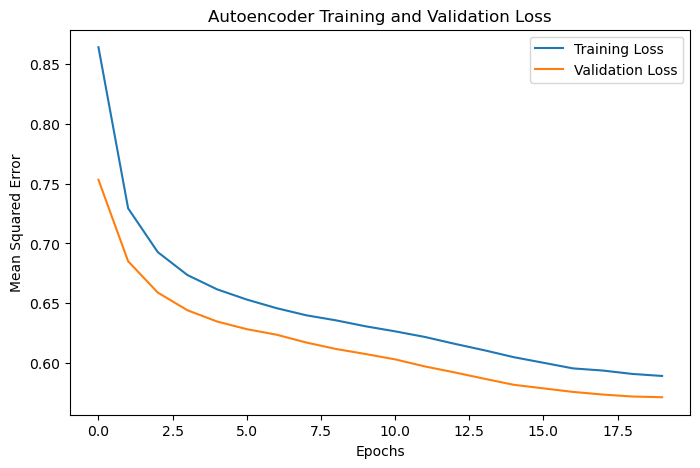

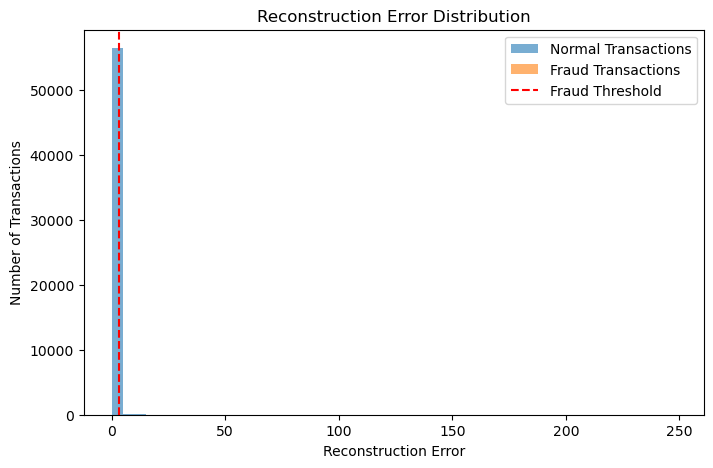

In [18]:

# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.show()


# Plot reconstruction errors

plt.figure(figsize=(8, 5))

plt.hist(test_errors[y_test.values == 0],
         bins=50, alpha=0.6, label='Normal Transactions')

plt.hist(test_errors[y_test.values == 1],
         bins=50, alpha=0.6, label='Fraud Transactions')

plt.axvline(threshold, color='red',
            linestyle='--', label='Fraud Threshold')

plt.title('Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Transactions')
plt.legend()
plt.show()
